<a href="https://colab.research.google.com/github/Bilal-data/online-retail-analysis/blob/main/online_retail_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [42]:
!wget -q -O retail.zip "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
!unzip -o retail.zip
!ls -lh

Archive:  retail.zip
 extracting: Online Retail.xlsx      
total 46M
-rwx------ 1 root root  23M May 22  2023 'Online Retail.xlsx'
-rw-r--r-- 1 root root  23M Nov 22 23:20  retail.zip
drwxr-xr-x 1 root root 4.0K Nov 18 15:58  sample_data


In [43]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [44]:
df.isna().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [45]:
(df["Quantity"] < 0).sum()

np.int64(10624)

In [46]:
df[df["Quantity"] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [47]:
neg = df[df["Quantity"] < 0]
neg["InvoiceNo"].astype(str).str.startswith("C").sum()

np.int64(9288)

In [48]:
not_c = neg[~neg["InvoiceNo"].astype(str).str.startswith("C")]
print(len(not_c))
not_c.head()

1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom


In [49]:
sales = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
print(len(sales))
print(len(df) - len(sales))

530104
11805


In [50]:
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]
sales["Revenue"].sum()

np.float64(10666684.544)

In [51]:
by_country = sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
(by_country / by_country.sum() * 100).round(1).head(5)

,Revenue
Country,
United Kingdom,84.6
Netherlands,2.7
EIRE,2.7
Germany,2.1
France,2.0


In [52]:
monthly = sales.groupby(sales["InvoiceDate"].dt.to_period("M"))["Revenue"].sum().round(0)
monthly

,Revenue
InvoiceDate,
2010-12,823746.0
2011-01,691365.0
2011-02,523632.0
2011-03,717639.0
2011-04,537809.0
2011-05,770536.0
2011-06,761740.0
2011-07,719221.0
2011-08,759138.0


In [53]:
sales["InvoiceDate"].max()

Timestamp('2011-12-09 12:50:00')

In [54]:
d10 = sales[(sales["InvoiceDate"] >= "2010-12-01") & (sales["InvoiceDate"] < "2010-12-10")]["Revenue"].sum()
d11 = sales[(sales["InvoiceDate"] >= "2011-12-01") & (sales["InvoiceDate"] < "2011-12-10")]["Revenue"].sum()
print(round(d10), round(d11))

438853 638793


In [55]:
p10 = (sales["InvoiceDate"] >= "2010-12-01") & (sales["InvoiceDate"] < "2010-12-10")
p11 = (sales["InvoiceDate"] >= "2011-12-01") & (sales["InvoiceDate"] < "2011-12-10")
print(sales[p10]["InvoiceNo"].nunique(), sales[p11]["InvoiceNo"].nunique())

834 819


In [56]:
inv10 = sales[p10].groupby("InvoiceNo")["Revenue"].sum().sort_values(ascending=False)
inv11 = sales[p11].groupby("InvoiceNo")["Revenue"].sum().sort_values(ascending=False)
print(inv10.head(3).round(0).tolist())
print(inv11.head(3).round(0).tolist())

[15885.0, 13541.0, 11540.0]
[168470.0, 10902.0, 10364.0]


In [57]:
big = sales["Revenue"].idxmax()
sales.loc[[big], ["InvoiceNo", "Description", "Quantity", "UnitPrice", "InvoiceDate", "Country"]]

,InvoiceNo,Description,Quantity,UnitPrice,InvoiceDate,Country
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,United Kingdom


In [58]:
df[df["Quantity"].abs() == 80995][["InvoiceNo", "Description", "Quantity", "UnitPrice", "InvoiceDate"]]

,InvoiceNo,Description,Quantity,UnitPrice,InvoiceDate
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00
540422,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,2011-12-09 09:27:00


In [59]:
net = df[df["UnitPrice"] > 0].copy()
net["Revenue"] = net["Quantity"] * net["UnitPrice"]
n10 = net[(net["InvoiceDate"] >= "2010-12-01") & (net["InvoiceDate"] < "2010-12-10")]["Revenue"].sum()
n11 = net[(net["InvoiceDate"] >= "2011-12-01") & (net["InvoiceDate"] < "2011-12-10")]["Revenue"].sum()
print(round(n10), round(n11), round((n11 / n10 - 1) * 100, 1))

377488 433668 14.9


In [60]:
monthly_net = net.groupby(net["InvoiceDate"].dt.to_period("M"))["Revenue"].sum().round(0)
monthly_net

,Revenue
InvoiceDate,
2010-12,748957.0
2011-01,560000.0
2011-02,498063.0
2011-03,683267.0
2011-04,493207.0
2011-05,723334.0
2011-06,691123.0
2011-07,681300.0
2011-08,704805.0


In [61]:
inv = sales.groupby("InvoiceNo").agg(country=("Country", "first"), total=("Revenue", "sum"))
print(len(inv))
inv.head()

19960


,country,total
InvoiceNo,,
536365,United Kingdom,139.12
536366,United Kingdom,22.20
536367,United Kingdom,278.73
536368,United Kingdom,70.05
536369,United Kingdom,17.85


In [62]:
inv["is_uk"] = inv["country"] == "United Kingdom"
inv.groupby("is_uk")["total"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
is_uk,,,
False,1941,845.7,424.1
True,18019,500.9,300.5


In [63]:
import numpy as np

vals = inv["total"].to_numpy()
is_uk = inv["is_uk"].to_numpy()
k = (~is_uk).sum()  # عدد فواتير باقي الدول

obs_mean = vals[~is_uk].mean() - vals[is_uk].mean()
obs_med = np.median(vals[~is_uk]) - np.median(vals[is_uk])

rng = np.random.default_rng(42)
sim_mean = np.empty(10_000)
sim_med = np.empty(10_000)
for i in range(10_000):
    pick = rng.choice(len(vals), size=k, replace=False)
    mask = np.zeros(len(vals), dtype=bool)
    mask[pick] = True
    sim_mean[i] = vals[mask].mean() - vals[~mask].mean()
    sim_med[i] = np.median(vals[mask]) - np.median(vals[~mask])

p_mean = (np.sum(np.abs(sim_mean) >= abs(obs_mean)) + 1) / 10_001
p_med = (np.sum(np.abs(sim_med) >= abs(obs_med)) + 1) / 10_001
print("mean diff:", round(obs_mean, 1), "p =", p_mean)
print("median diff:", round(obs_med, 1), "p =", p_med)

mean diff: 344.8 p = 9.999000099990002e-05
median diff: 123.6 p = 9.999000099990002e-05


In [64]:
canc = df[df["InvoiceNo"].astype(str).str.startswith("C")].copy()
canc["Value"] = -canc["Quantity"] * canc["UnitPrice"]
print(canc["InvoiceNo"].nunique(), round(canc["Value"].sum()))
print(round(canc["Value"].sum() / sales["Revenue"].sum() * 100, 1))

3836 896812
8.4


In [65]:
known = sales[sales["CustomerID"].notna()]
cust = known.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False)
print(len(cust))
print(round(cust.head(10).sum() / cust.sum() * 100, 1))

4338
17.3


In [66]:
n20 = int(len(cust) * 0.2)
print(n20, round(cust.head(n20).sum() / cust.sum() * 100, 1))

867 74.6


## Invoice size, cancellations and customers

- Invoice table (gross view): 19,960 invoices. The mean invoice is 845.7 outside the UK (1,941 invoices) against 500.9 in the UK (18,019). Medians: 424.1 against 300.5.
- Permutation test (10,000 shuffles of invoices, two-sided): p < 0.0001 for the mean difference (344.8) and for the median difference (123.6). The gap is very unlikely to be chance, and it also holds for the median, so it is not only a few large invoices.
- Limits: the test shows the gap is not chance, not why (wholesale buyers is my guess). Invoices of the same customer are not independent, and I could not shuffle by customer because 25% of rows have no CustomerID.
- Cancellations: 3,836 cancellation invoices worth 896,812, which is 8.4% of gross revenue. This compares values in the same period, so some cancellations may refer to earlier sales.
- Customers: 4,338 customers with an ID. The top 10 bring 17.3% of their revenue and the top 20% (867 customers) bring 74.6%. Revenue is concentrated in a small group (gross view, rows with a CustomerID only).

In [67]:
inv2 = sales.groupby("InvoiceNo").agg(customer=("CustomerID", "first"), country=("Country", "first"), total=("Revenue", "sum"))
known_inv = inv2.dropna(subset=["customer"])
cust_tab = known_inv.groupby("customer").agg(country=("country", "first"), invoices=("total", "size"), avg_invoice=("total", "mean"))
cust_tab["is_uk"] = cust_tab["country"] == "United Kingdom"
print(len(cust_tab))
print(cust_tab.groupby("is_uk")["avg_invoice"].agg(["count", "mean", "median"]).round(1))

4338
       count   mean  median
is_uk                      
False    418  661.5   424.7
True    3920  393.3   281.6


In [68]:
cvals = cust_tab["avg_invoice"].to_numpy()
c_uk = cust_tab["is_uk"].to_numpy()
k2 = (~c_uk).sum()  # عدد عملاء خارج بريطانيا

obs_mean2 = cvals[~c_uk].mean() - cvals[c_uk].mean()
obs_med2 = np.median(cvals[~c_uk]) - np.median(cvals[c_uk])

rng2 = np.random.default_rng(42)
sim_mean2 = np.empty(10_000)
sim_med2 = np.empty(10_000)
for i in range(10_000):
    pick = rng2.choice(len(cvals), size=k2, replace=False)
    mask = np.zeros(len(cvals), dtype=bool)
    mask[pick] = True
    sim_mean2[i] = cvals[mask].mean() - cvals[~mask].mean()
    sim_med2[i] = np.median(cvals[mask]) - np.median(cvals[~mask])

p_mean2 = (np.sum(np.abs(sim_mean2) >= abs(obs_mean2)) + 1) / 10_001
p_med2 = (np.sum(np.abs(sim_med2) >= abs(obs_med2)) + 1) / 10_001
print("mean diff:", round(obs_mean2, 1), "p =", p_mean2)
print("median diff:", round(obs_med2, 1), "p =", p_med2)

mean diff: 268.2 p = 0.010498950104989501
median diff: 143.1 p = 9.999000099990002e-05


In [69]:
print(round((cust_tab["invoices"] > 1).mean() * 100, 1))
print(cust_tab["invoices"].median(), cust_tab["invoices"].max())

65.6
2.0 209


In [70]:
cust_tab["revenue"] = known_inv.groupby("customer")["total"].sum()
rep = cust_tab["invoices"] > 1
print(round(cust_tab.loc[rep, "revenue"].sum() / cust_tab["revenue"].sum() * 100, 1))

93.1


### Customer-level test and repeat purchase

- Shuffling by customer (4,338 known customers, UK vs other countries): mean difference 268.2 (p = 0.0105), median difference 143.1 (p < 0.0001). The invoice-level test overstated the evidence for the mean, but the median result holds.
- 65.6% of known customers bought more than once (median 2 invoices, max 209).
- These repeat customers account for 93.1% of known-customer revenue (gross view).
- Limits: only rows with a CustomerID (about 75%); one-year window, so a one-time customer may simply have started late; customers with more invoices add more revenue by construction; gross view does not subtract returns.

In [71]:
canc_lines = df[df["InvoiceNo"].astype(str).str.startswith("C")]
print(len(canc_lines), round(canc_lines["CustomerID"].notna().mean() * 100, 1))

9288 95.9


In [72]:
canc_k = canc_lines[canc_lines["CustomerID"].notna()]
bought = set(zip(sales["CustomerID"], sales["StockCode"]))
has = [(c, s) in bought for c, s in zip(canc_k["CustomerID"], canc_k["StockCode"])]
print(len(canc_k), round(sum(has) / len(canc_k) * 100, 1))

8905 89.4


In [73]:
miss = canc_k[~np.array(has)]
print(miss["StockCode"].value_counts().head(5))

StockCode
M        106
D         77
POST      56
CRUK      16
22941     10
Name: count, dtype: int64


In [74]:
codes = ["M", "D", "POST", "CRUK"]
print(df[df["StockCode"].isin(codes)].groupby("StockCode")["Description"].first())

StockCode
CRUK    CRUK Commission
D              Discount
M                Manual
POST            POSTAGE
Name: Description, dtype: object


In [75]:
nonprod = canc["StockCode"].isin(codes)
print(round(canc.loc[nonprod, "Value"].sum()), round(canc.loc[nonprod, "Value"].sum() / canc["Value"].sum() * 100, 1))

172285 19.2


In [76]:
sales_np = sales[~sales["StockCode"].isin(codes)]
canc_np = canc[~canc["StockCode"].isin(codes)]
print(round(canc_np["Value"].sum()), round(canc_np["Value"].sum() / sales_np["Revenue"].sum() * 100, 1))

724527 6.9


In [77]:
ref = sales["InvoiceDate"].max() + pd.Timedelta(days=1)
last = known.groupby("CustomerID")["InvoiceDate"].max()
recency = (ref - last).dt.days
print(recency.median())

51.0


In [78]:
cust_tab["recency"] = recency
print(round((cust_tab["recency"] <= 90).mean() * 100, 1))

66.6


In [79]:
important = (cust_tab["invoices"] > 1) & (cust_tab["recency"] <= 90)
print(round(important.mean() * 100, 1), round(cust_tab.loc[important, "revenue"].sum() / cust_tab["revenue"].sum() * 100, 1))

51.7 85.5


In [98]:
rep = cust_tab["invoices"] > 1
act = cust_tab["recency"] <= 90
seg = np.select(
    [rep & act, rep & ~act, ~rep & act, ~rep & ~act],
    ["important", "lapsed_repeat", "new_active", "lost_early"],
    default=""
)
print(pd.Series(seg).value_counts())

important        2243
lost_early        847
new_active        646
lapsed_repeat     602
Name: count, dtype: int64


In [99]:
monthly = net.groupby(net["InvoiceDate"].dt.to_period("M"))["Revenue"].sum()
print(monthly)

InvoiceDate
2010-12     748957.020
2011-01     560000.260
2011-02     498062.650
2011-03     683267.080
2011-04     493207.121
2011-05     723333.510
2011-06     691123.120
2011-07     681300.111
2011-08     704804.630
2011-09    1019687.622
2011-10    1070704.670
2011-11    1461756.250
2011-12     433668.010
Freq: M, Name: Revenue, dtype: float64


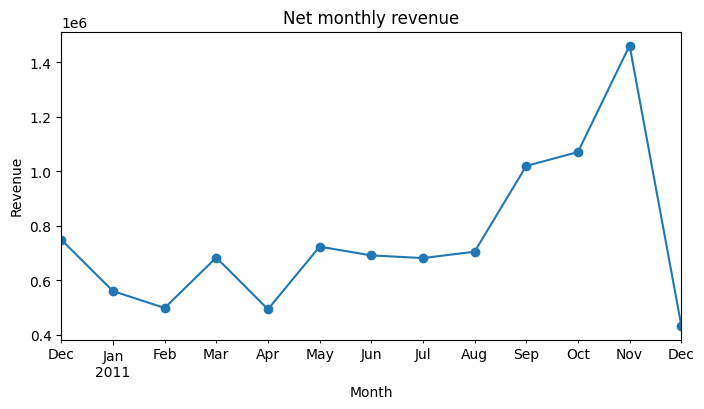

In [100]:
import matplotlib.pyplot as plt

monthly.plot(kind="line", marker="o", figsize=(8, 4))
plt.title("Net monthly revenue")
plt.ylabel("Revenue")
plt.xlabel("Month")
plt.show()

### Cancellation matching and seasonality

- Cancellation lines matched to a purchase by the same customer and stock code: 89.4% of cancellation lines with a CustomerID found one (this is a loose check, not proof of timing or quantity).
- Of the unmatched lines, about a quarter are non-product codes (M = Manual, D = Discount, POST = Postage, CRUK = CRUK Commission), which are 19.2% of total cancellation value.
- Excluding non-product codes, product cancellations are 6.9% of product sales (vs. 8.4% in the simple view).
- Repeat/recency segments (known customers): important (repeat and active) 2,243, lost_early 847, new_active 646, lapsed_repeat 602. The "important" segment (51.7% of customers) brings 85.5% of revenue.
- Monthly net revenue rises from January to a sharp peak in November 2011, then drops in December (incomplete month). One year of data, so this is not proven to be a yearly pattern.